# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O título e a apresentação originais são mantidos como registro do roteiro da aula. A execução passa a analisar o **Electric Vehicle (EV) Charging Dataset** (versão sintética, `SYNTHETIC_EV_DATA.csv`), disponível originalmente em [Kaggle — Electric Vehicle Charging Dataset](https://www.kaggle.com/datasets/mexwell/electric-vehicle-charging-dataset).
>
> **Por quê:** Preservar o texto-base permite comparar a aplicação dos mesmos princípios de EDA em outro domínio (energia/mobilidade elétrica), reaproveitando o roteiro validado em aula.

## Sobre o dataset

O **Electric Vehicle Charging Dataset** descreve sessões individuais de recarga de veículos elétricos em um conjunto de estações. Segundo a página do Kaggle, cada linha registra o horário de conexão, a duração da recarga, a energia consumida e um índice de dia da sessão. O arquivo local usado aqui (`SYNTHETIC_EV_DATA.csv`) é a versão **sintética** do dataset, com aproximadamente **1,97 milhão de sessões** e 4 colunas:

| Coluna original | Descrição |
|---|---|
| `connectionTime_decimal` | Horário de conexão do veículo à estação, em formato decimal de 0 a 24h (ex.: 14.5 = 14h30) |
| `chargingDuration` | Duração da sessão de recarga, em horas |
| `kWhDelivered` | Energia entregue ao veículo durante a sessão, em kWh |
| `dayIndicator` | Índice sequencial do dia da simulação (1 a 29.600) — **não** é, como o nome sugere à primeira vista, um indicador binário de dia da semana |

Diferente do dataset de filmes (1.000 linhas, muitas colunas textuais), este dataset tem **poucas colunas, todas numéricas, e um volume de linhas ~2.000x maior**. Isso muda decisões práticas ao longo da EDA (ex.: usar amostras para alguns gráficos e testes) — cada uma dessas decisões é justificada no momento em que aparece.

## Setup de Bibliotecas e Dados

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** As bibliotecas estatísticas e gráficas são mantidas; o carregamento usa o CSV local e inclui a criação das variáveis qualitativas derivadas usadas ao longo da análise.
>
> **Por quê:** O arquivo local elimina a dependência de download durante a execução, e as variáveis derivadas (dia útil/fim de semana, período do dia) tornam possível a análise relacional em um dataset originalmente composto só por variáveis quantitativas.

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 30)

COR_NEUTRA = "#b8b8b8"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "#c43c39"

# Semente fixa para todas as amostragens usadas neste notebook (reprodutibilidade)
SEED = 42
rng = np.random.default_rng(SEED)

## Carregando o Dataset

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O dataset Heart Disease é substituído pelo arquivo local `SYNTHETIC_EV_DATA.csv`.
>
> **Por quê:** Esse é o novo conjunto de dados e o uso local evita espera indefinida por rede ou autenticação no Kaggle.

In [4]:
ARQUIVO_DADOS = Path("SYNTHETIC_EV_DATA.csv")

if not ARQUIVO_DADOS.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_DADOS.resolve()}\n"
        "Coloque o CSV na mesma pasta deste notebook."
    )

df_bruto = pd.read_csv(ARQUIVO_DADOS)

MAPA_COLUNAS = {
    "connectionTime_decimal": "hora_conexao",
    "chargingDuration": "duracao_carga_h",
    "kWhDelivered": "energia_kwh",
    "dayIndicator": "indice_dia",
}

df = df_bruto.rename(columns=MAPA_COLUNAS).copy()

# --- Variáveis qualitativas derivadas ---
# `indice_dia` vai de 1 a 29.600 (não é um indicador binário de fim de semana).
# Como o dataset não documenta a que data de calendário cada índice corresponde,
# assumimos um ciclo hipotético de 7 dias a partir do índice para ilustrar uma
# comparação "dia útil x fim de semana". Essa suposição é deixada explícita
# (rótulos com "(assumido)") e é testada mais adiante: se não houver diferença
# estatística real entre os grupos, isso é evidência de que o índice NÃO
# codifica dia da semana de fato.
df["posicao_ciclo_semanal"] = (df["indice_dia"] - 1) % 7
df["tipo_dia"] = np.where(
    df["posicao_ciclo_semanal"].isin([5, 6]),
    "Fim de semana (assumido)",
    "Dia útil (assumido)",
)

def classificar_periodo(hora):
    if hora < 6:
        return "Madrugada"
    elif hora < 12:
        return "Manhã"
    elif hora < 18:
        return "Tarde"
    return "Noite"

df["periodo_dia"] = df["hora_conexao"].apply(classificar_periodo)
df["periodo_dia"] = pd.Categorical(
    df["periodo_dia"], categories=["Madrugada", "Manhã", "Tarde", "Noite"], ordered=True
)

df_antes_tratamento = df.copy(deep=True)

print(f"Arquivo carregado: {ARQUIVO_DADOS.resolve()}")
print(f"Linhas: {df.shape[0]:,} | Colunas originais e derivadas: {df.shape[1]}")
display(df.head(3))

Arquivo carregado: /content/SYNTHETIC_EV_DATA.csv
Linhas: 191,466 | Colunas originais e derivadas: 7


,hora_conexao,duracao_carga_h,energia_kwh,indice_dia,posicao_ciclo_semanal,tipo_dia,periodo_dia
0,15.332910,2.301191,11.469551,1,0,Dia útil (assumido),Tarde
1,16.811495,4.941774,3.611695,1,0,Dia útil (assumido),Tarde
2,21.151696,3.567173,14.455706,1,0,Dia útil (assumido),Noite


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas, milhares?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.
>
> **Resposta à discussão:** A base bruta possui exatamente **1.965.239 sessões de recarga e 4 colunas**. Após a preparação, o número de colunas sobe para 6 pela criação de `tipo_dia` e `periodo_dia`. É um volume ~2.000x maior que o dataset de filmes usado na aula — decorrência de ser um dataset sintético de simulação (sessões geradas ao longo de 29.600 dias), e não um recorte de eventos reais catalogados manualmente.

### Dimensão e Tipos de Dados

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [5]:
print(f"O dataset possui {df.shape[0]:,} sessões de recarga e {df.shape[1]} colunas após a preparação inicial.")
df.shape

O dataset possui 191,466 sessões de recarga e 7 colunas após a preparação inicial.


(191466, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191466 entries, 0 to 191465
Data columns (total 7 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   hora_conexao           191466 non-null  float64 
 1   duracao_carga_h        191466 non-null  float64 
 2   energia_kwh            191466 non-null  float64 
 3   indice_dia             191466 non-null  int64   
 4   posicao_ciclo_semanal  191466 non-null  int64   
 5   tipo_dia               191466 non-null  object  
 6   periodo_dia            191466 non-null  category
dtypes: category(1), float64(3), int64(2), object(1)
memory usage: 8.9+ MB


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hora_conexao,191466.0,NaN,NaN,NaN,14.524094,6.402352,0.000464,14.311493,16.174303,18.058544,23.999296
duracao_carga_h,191466.0,NaN,NaN,NaN,3.797993,3.369873,0.000044,1.448527,2.553073,5.428739,37.187498
energia_kwh,191466.0,NaN,NaN,NaN,9.464223,5.720569,0.000766,4.890923,9.226245,13.572241,61.287649
indice_dia,191466.0,NaN,NaN,NaN,1446.314505,837.58378,1.0,722.0,1439.0,2172.0,2896.0
posicao_ciclo_semanal,191466.0,NaN,NaN,NaN,2.989889,2.012764,0.0,1.0,3.0,5.0,6.0
tipo_dia,191466,2,Dia útil (assumido),136147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
periodo_dia,191466,4,Tarde,105284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Duplicadas

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [8]:
duplicadas_completas = int(df_bruto.duplicated().sum())
print(f"Linhas completamente duplicadas: {duplicadas_completas}")
print(f"Percentual do total: {100 * duplicadas_completas / len(df_bruto):.4f}%")

Linhas completamente duplicadas: 0
Percentual do total: 0.0000%


> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Nenhuma linha duplicada é removida.
>
> **Por quê:** **Justificativa de passo não executado:** o teste acima retorna **0 linhas duplicadas**. Como as três variáveis numéricas são de ponto flutuante contínuo com muitas casas decimais, a chance de duas sessões terem exatamente o mesmo `hora_conexao`, `duracao_carga_h` e `energia_kwh` por acaso é praticamente nula — o que é coerente com um gerador sintético contínuo. Não há, portanto, decisão de remoção a ser tomada nesta etapa.

### Renomeando variáveis

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** As colunas originais em inglês (`connectionTime_decimal`, `chargingDuration`, `kWhDelivered`, `dayIndicator`) foram renomeadas para nomes em português (`hora_conexao`, `duracao_carga_h`, `energia_kwh`, `indice_dia`) já na célula de carregamento, para manter a consistência com o restante do notebook.
>
> **Por quê:** **Justificativa de passo adaptado:** diferente do dataset de filmes, aqui não existe uma variável-alvo clínica ou de negócio a ser simplificada (como `num` → `doenca_cardiaca`). O dataset de EV não tem um rótulo original; por isso, a etapa de \"renomear o atributo-alvo\" não se aplica da mesma forma. Em vez disso, a variável qualitativa `tipo_dia` foi **criada** (não renomeada) para servir de agrupamento de contraste ao longo da análise bivariada, de forma equivalente ao papel que `doenca_cardiaca` cumpre no roteiro original.

In [9]:
display(df[["tipo_dia", "periodo_dia"]].describe(include="all").T)
print()
print("Distribuição de tipo_dia:")
display(df["tipo_dia"].value_counts().to_frame("sessoes"))

,count,unique,top,freq
tipo_dia,191466,2,Dia útil (assumido),136147
periodo_dia,191466,4,Tarde,105284



Distribuição de tipo_dia:


,sessoes
tipo_dia,
Dia útil (assumido),136147
Fim de semana (assumido),55319


## 2. Dados Faltantes

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [10]:
ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": df.isna().mean().mul(100),
}).sort_values(["ausentes", "percentual"], ascending=False)

ausentes

,ausentes,percentual
hora_conexao,0,0.0
duracao_carga_h,0,0.0
energia_kwh,0,0.0
indice_dia,0,0.0
posicao_ciclo_semanal,0,0.0
tipo_dia,0,0.0
periodo_dia,0,0.0


**Discussão:** Alguma feature tem dados ausentes nos seus dados?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A discussão é respondida diretamente pela tabela acima, sem necessidade de conversões de texto para número (diferente do dataset de filmes).
>
> **Por quê:** Todas as colunas originais já nasceram numéricas (`float64`/`int64`), então não há o problema de valores textuais que viram `NaN` na conversão.
>
> **Resposta à discussão:** **Não.** Nenhuma das 6 colunas (originais ou derivadas) tem valores ausentes — `df.isna().sum()` é zero em todas. Isso é coerente com a natureza do dataset: sendo uma versão *sintética* gerada por simulação, é esperado que o processo de geração produza um valor numérico para cada sessão em cada variável, sem as falhas de coleta, digitação ou parsing típicas de dados reais (como orçamento ou classificação ausentes no dataset de filmes).

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** As seções de mecanismo de ausência (MCAR/MAR/MNAR), coocorrência de ausências (heatmap) e decisão de tratamento de ausentes são **omitidas** nesta entrega.
>
> **Por quê:** **Justificativa de passos não executados:** com 0% de valores ausentes em todas as colunas, não há nada a diagnosticar (não existe padrão de coocorrência a medir, pois não existem ausências) nem a tratar (não há decisão de imputar ou remover linhas por ausência). Manter essas subseções aqui seria simular uma análise sobre um problema que, neste dataset, simplesmente não existe. Retomamos o tratamento de dados na Seção 4, focado inteiramente em outliers, que é o problema de qualidade de dado relevante para este dataset.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido reportar a mediana do que a média, ou aplicar uma transformação antes de certos testes.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [11]:
VARS_QUANT = ["hora_conexao", "duracao_carga_h", "energia_kwh"]
VARS_QUALI = ["tipo_dia", "periodo_dia"]

df[VARS_QUANT].describe().T

,count,mean,std,min,25%,50%,75%,max
hora_conexao,191466.0,14.524094,6.402352,0.000464,14.311493,16.174303,18.058544,23.999296
duracao_carga_h,191466.0,3.797993,3.369873,0.000044,1.448527,2.553073,5.428739,37.187498
energia_kwh,191466.0,9.464223,5.720569,0.000766,4.890923,9.226245,13.572241,61.287649


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Assimetria e curtose são avaliadas nas três variáveis quantitativas do dataset de EV.
>
> **Por quê:** Diferente dos valores financeiros do dataset de filmes, aqui as variáveis são horas e kWh, mas o mesmo diagnóstico de assimetria orienta as mesmas decisões (transformação, escolha de mediana vs. média, testes não paramétricos).
>
> **Resposta à discussão:** As maiores assimetrias aparecem em **duracao_carga_h (skew ≈ 2,175; kurtose ≈ 8,704)** e **energia_kwh (skew ≈ 1,278; kurtose ≈ 4,935)** — ambas com cauda direita pesada, ou seja, a maioria das sessões é curta/de baixo consumo, mas existe uma cauda de sessões bem mais longas ou de recarga bem mais intensa. Já `hora_conexao` tem assimetria **negativa e moderada (skew ≈ -1,080)**, com curtose próxima de zero (≈ 0,056): a distribuição é concentrada nos horários de tarde/noite, com uma cauda mais longa em direção à madrugada.

In [12]:
estatisticas_forma = df[VARS_QUANT].agg(["skew"]).T
estatisticas_forma["kurtosis"] = df[VARS_QUANT].kurt()
estatisticas_forma.columns = ["skewness", "kurtosis"]
estatisticas_forma

,skewness,kurtosis
hora_conexao,-1.093424,0.098323
duracao_carga_h,2.148436,8.524438
energia_kwh,1.285109,4.951023


### Distribuições de dados

Onde fizer sentido, comparamos "Dia útil (assumido)" (cinza) vs. "Fim de semana (assumido)" (vermelho). Vamos utilizar esta convenção de cor até a análise bivariada.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base. Como o dataset tem ~2 milhões de linhas, os histogramas usam uma amostra aleatória de 100.000 sessões (`SEED = 42`) apenas para a etapa de KDE (estimativa de densidade), que é computacionalmente cara em bases muito grandes; as estatísticas numéricas (skewness, kurtose, quantis) continuam calculadas sobre a base completa.

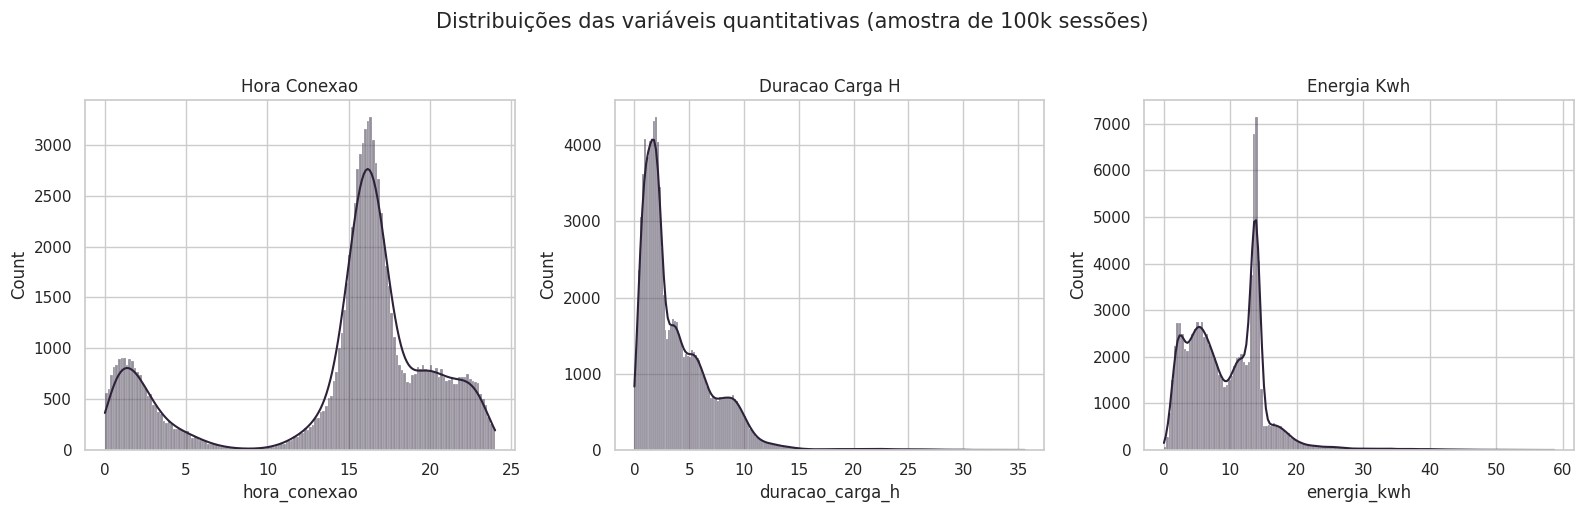

In [13]:
AMOSTRA_PLOT = df.sample(100_000, random_state=SEED)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, coluna in zip(axes, VARS_QUANT):
    sns.histplot(AMOSTRA_PLOT[coluna], kde=True, color=COR_DESTAQUE, ax=ax)
    ax.set_title(coluna.replace("_", " ").title())

fig.suptitle("Distribuições das variáveis quantitativas (amostra de 100k sessões)", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

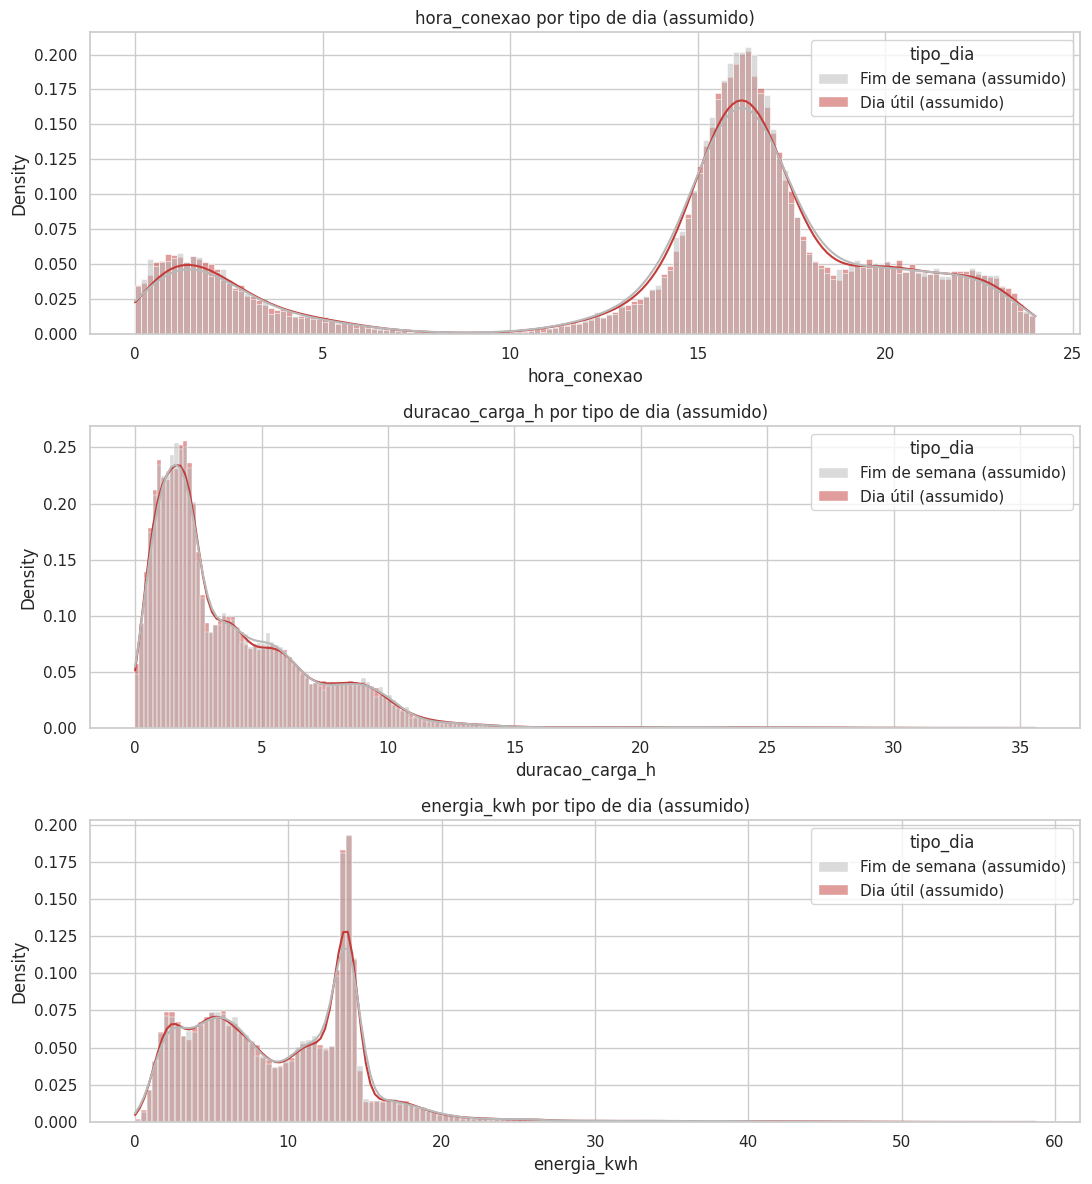

In [14]:
fig, axes = plt.subplots(len(VARS_QUANT), 1, figsize=(11, 12))

for ax, coluna in zip(axes, VARS_QUANT):
    sns.histplot(
        data=AMOSTRA_PLOT,
        x=coluna,
        hue="tipo_dia",
        palette=[COR_NEUTRA, COR_ALERTA],
        kde=True,
        stat="density",
        common_norm=False,
        ax=ax,
    )
    ax.set_title(f"{coluna} por tipo de dia (assumido)")

plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados, fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Dia útil" e "Fim de semana"?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A comparação \"Normal\" versus \"Cardíaco\" é substituída por `Dia útil (assumido)` versus `Fim de semana (assumido)`, derivados de `indice_dia`.
>
> **Por quê:** É o único agrupamento qualitativo disponível no dataset original, criado para permitir a lógica pedagógica de comparação entre distribuições.
>
> **Resposta à discussão:** **Visualmente, não.** As curvas de `hora_conexao`, `duracao_carga_h` e `energia_kwh` praticamente se sobrepõem entre os dois grupos assumidos. Isso já é um indício (confirmado estatisticamente na Seção 6) de que a suposição de ciclo semanal de 7 dias a partir de `indice_dia` **não** captura nenhum padrão real de dia útil vs. fim de semana no comportamento de recarga — o que é esperado, já que o próprio nome da coluna (`dayIndicator`) sugere apenas um contador sequencial de dias de simulação, não uma codificação de calendário.

#### Testes de Aderência

*Será que a energia entregue segue uma distribuição normal?*

O **Shapiro-Wilk** como teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** **Justificativa de adaptação de execução:** a implementação do scipy para Shapiro-Wilk desaconselha (e antigamente limitava) o uso em amostras muito grandes — com ~2 milhões de linhas o teste tende a rejeitar a normalidade quase sempre por puro poder estatístico, mesmo para pequenos desvios sem relevância prática. Por isso, o teste é aplicado a uma **amostra aleatória de 5.000 sessões** (`SEED = 42`), prática recomendada para esse teste em bases grandes.
>
> **Resposta à discussão:** Nenhuma das três variáveis segue distribuição normal: Shapiro-Wilk rejeita a normalidade com `p < 0,001` para `hora_conexao`, `duracao_carga_h` e `energia_kwh`. Isso é visualmente confirmado pelos QQ-plots, cujos pontos se afastam da reta de referência nas extremidades.

In [15]:
amostra_shapiro = df.sample(5_000, random_state=SEED)

resultados_shapiro = []
for coluna in VARS_QUANT:
    estatistica, p_valor = stats.shapiro(amostra_shapiro[coluna])
    resultados_shapiro.append({
        "variavel": coluna,
        "W": estatistica,
        "p_valor": p_valor,
        "rejeita_normalidade_5pct": p_valor < 0.05,
    })

pd.DataFrame(resultados_shapiro).style.format({"W": "{:.4f}", "p_valor": "{:.3e}"})

,variavel,W,p_valor,rejeita_normalidade_5pct
0,hora_conexao,0.8212,1.708e-59,True
1,duracao_carga_h,0.8216,1.906e-59,True
2,energia_kwh,0.9037,1.419e-48,True


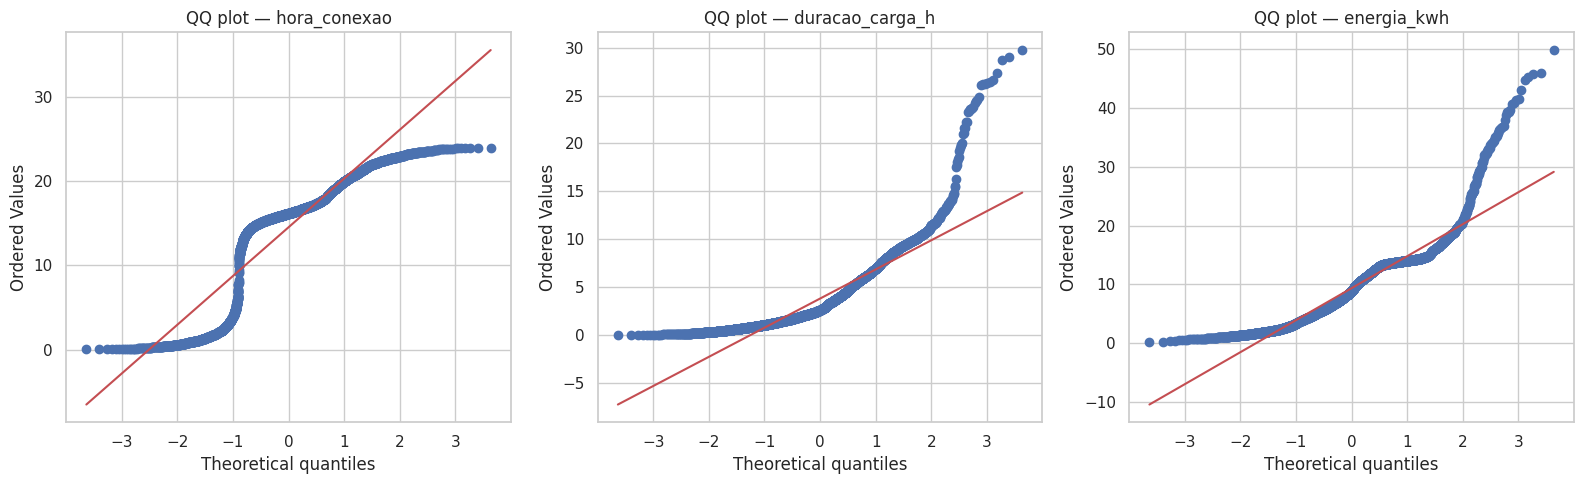

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, coluna in zip(axes, VARS_QUANT):
    stats.probplot(amostra_shapiro[coluna], dist="norm", plot=ax)
    ax.set_title(f"QQ plot — {coluna}")
plt.tight_layout()
plt.show()

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A ECDF passa a comparar a distribuição de `energia_kwh` entre `Dia útil` e `Fim de semana` (assumidos), usando a amostra de 100k sessões já usada nos histogramas.
>
> **Por quê:** Energia entregue é a medida mais diretamente relacionada ao uso da infraestrutura de recarga, sendo um bom candidato para investigar diferenças entre os grupos assumidos.

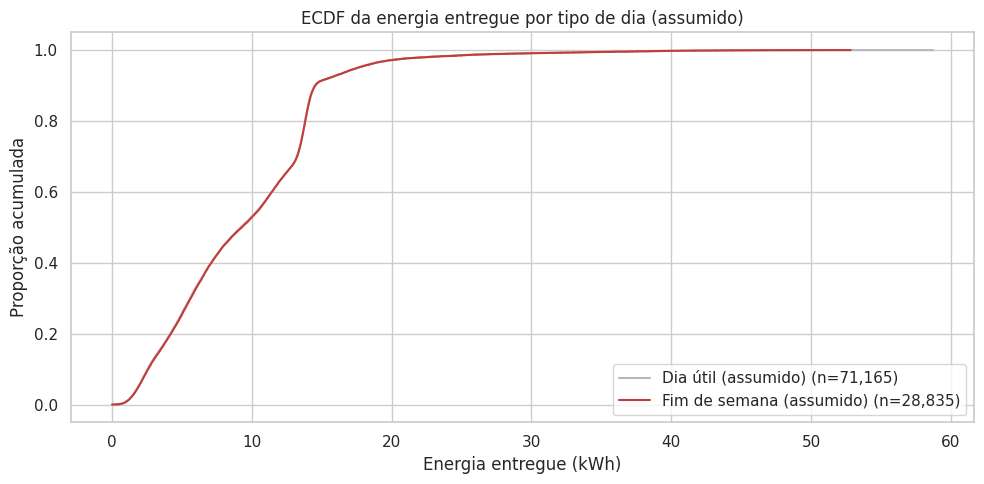

In [17]:
plt.figure(figsize=(10, 5))
for grupo, cor in [("Dia útil (assumido)", COR_NEUTRA), ("Fim de semana (assumido)", COR_ALERTA)]:
    serie = np.sort(AMOSTRA_PLOT.loc[AMOSTRA_PLOT["tipo_dia"] == grupo, "energia_kwh"])
    ecdf = np.arange(1, len(serie) + 1) / len(serie)
    plt.step(serie, ecdf, where="post", label=f"{grupo} (n={len(serie):,})", color=cor)

plt.xlabel("Energia entregue (kWh)")
plt.ylabel("Proporção acumulada")
plt.title("ECDF da energia entregue por tipo de dia (assumido)")
plt.legend()
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das sessões desse grupo entregou até aquela quantidade de energia". Curvas praticamente sobrepostas indicam que os dois grupos têm comportamento de energia muito parecido.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Nenhuma modificação de conteúdo; a leitura é direta do gráfico gerado.
>
> **Por quê:** A ECDF reforça visualmente o que já apareceu nos histogramas por grupo.
>
> **Resposta à discussão:** **As duas curvas praticamente coincidem em toda a faixa de energia**, reforçando que a suposição de ciclo semanal não separa comportamentos de recarga diferentes — mais um indício de que `indice_dia` não codifica dia da semana real.

### Métricas de Tendência Central

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

Média:   9.46 kWh
Mediana: 9.23 kWh
Razão média/mediana: 1.03


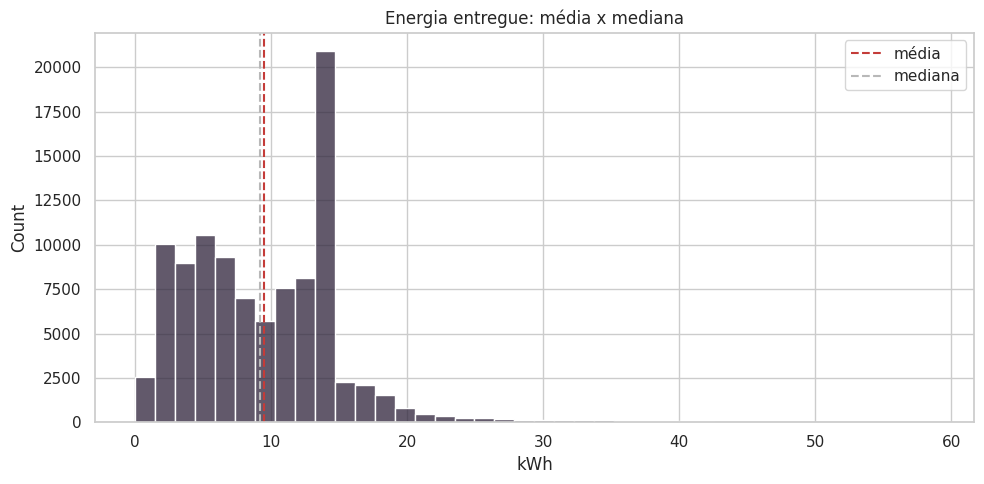

In [18]:
media_energia = df["energia_kwh"].mean()
mediana_energia = df["energia_kwh"].median()

print(f"Média:   {media_energia:.2f} kWh")
print(f"Mediana: {mediana_energia:.2f} kWh")
print(f"Razão média/mediana: {media_energia / mediana_energia:.2f}")

plt.figure(figsize=(10, 5))
sns.histplot(AMOSTRA_PLOT["energia_kwh"], bins=40, color=COR_DESTAQUE)
plt.axvline(media_energia, color=COR_ALERTA, linestyle="--", label="média")
plt.axvline(mediana_energia, color=COR_NEUTRA, linestyle="--", label="mediana")
plt.title("Energia entregue: média x mediana")
plt.xlabel("kWh")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

,std,var,min,max,amplitude
hora_conexao,6.402352,40.990117,0.000464,23.999296,23.998832
duracao_carga_h,3.369873,11.356041,0.000044,37.187498,37.187454
energia_kwh,5.720569,32.724907,0.000766,61.287649,61.286883


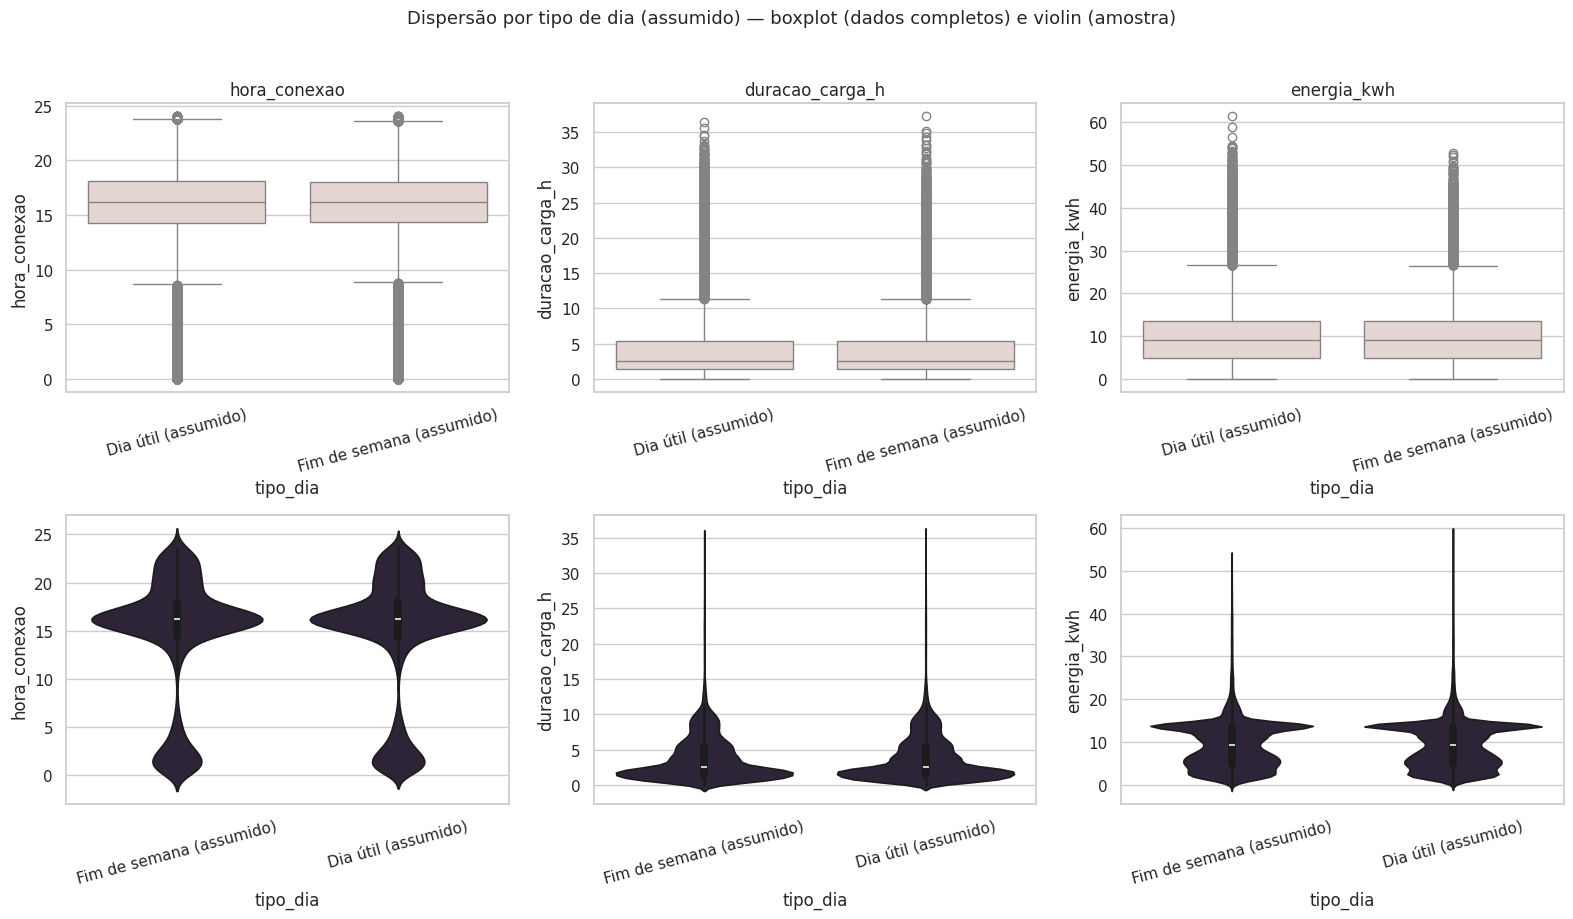

In [19]:
dispersao = df[VARS_QUANT].agg(["std", "var", "min", "max"]).T
dispersao["amplitude"] = dispersao["max"] - dispersao["min"]
display(dispersao)

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(16, 9))
for indice, coluna in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="tipo_dia", y=coluna, color=COR_CONTEXTO, ax=axes[0, indice])
    sns.violinplot(data=AMOSTRA_PLOT, x="tipo_dia", y=coluna, color=COR_DESTAQUE, ax=axes[1, indice])
    axes[0, indice].set_title(coluna)
    axes[0, indice].tick_params(axis="x", rotation=15)
    axes[1, indice].tick_params(axis="x", rotation=15)

fig.suptitle("Dispersão por tipo de dia (assumido) — boxplot (dados completos) e violin (amostra)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre os dois grupos? Isso já seria um indício — antes mesmo da análise bivariada formal — de que a variável ajuda a diferenciar as duas classes.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Boxplots (base completa) e violin plots (amostra) comparam as três variáveis quantitativas entre `Dia útil` e `Fim de semana` (assumidos).
>
> **Por quê:** O boxplot na base completa garante que os quantis retratados sejam exatos; o violin na amostra evita o custo computacional de estimar densidade em ~2 milhões de pontos.
>
> **Resposta à discussão:** **Não.** As caixas e os formatos dos violinos são visualmente quase idênticos entre os dois grupos nas três variáveis — consistente com o padrão já visto nos histogramas e na ECDF: a suposição de ciclo semanal de 7 dias não parece corresponder a nenhuma diferença real de comportamento de recarga.

## 4. Tratamento de Dados Ausentes e Outliers

Como já vimos na Seção 2 que **não há dados ausentes**, esta seção foca inteiramente na detecção e decisão sobre outliers.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos, sem a etapa de tratamento de ausentes (não aplicável — ver Seção 2).
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.
>
> **Resposta à discussão:** O IQR sinaliza **379.579 sessões (19,31%)** em `hora_conexao`, **44.192 (2,25%)** em `duracao_carga_h` e **22.693 (1,15%)** em `energia_kwh`. O percentual alto em `hora_conexao` chama atenção — mas decorre da forte assimetria negativa da variável (concentrada à tarde/noite), não de erros de coleta: o próprio limite inferior calculado pelo IQR (≈ 8,56h) já é menor que o mínimo teoricamente possível da variável em muitos contextos, e o limite superior (≈ 23,73h) está dentro do intervalo válido de 0–24h. Ou seja, o critério estatístico do IQR reage à forma da distribuição, não a valores fisicamente inválidos.

In [20]:
resumo_outliers = []
for coluna in VARS_QUANT:
    serie = df[coluna]
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara_outlier = (serie < limite_inferior) | (serie > limite_superior)
    resumo_outliers.append({
        "variavel": coluna,
        "n_validos": len(serie),
        "outliers_iqr": int(mascara_outlier.sum()),
        "percentual": 100 * mascara_outlier.mean(),
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
    })

pd.DataFrame(resumo_outliers).style.format({
    "percentual": "{:.2f}%",
    "limite_inferior": "{:.3f}",
    "limite_superior": "{:.3f}",
})

,variavel,n_validos,outliers_iqr,percentual,limite_inferior,limite_superior
0,hora_conexao,191466,36717,19.18%,8.691,23.679
1,duracao_carga_h,191466,4321,2.26%,-4.522,11.399
2,energia_kwh,191466,2276,1.19%,-8.131,26.594


### Visualizando os Outliers

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

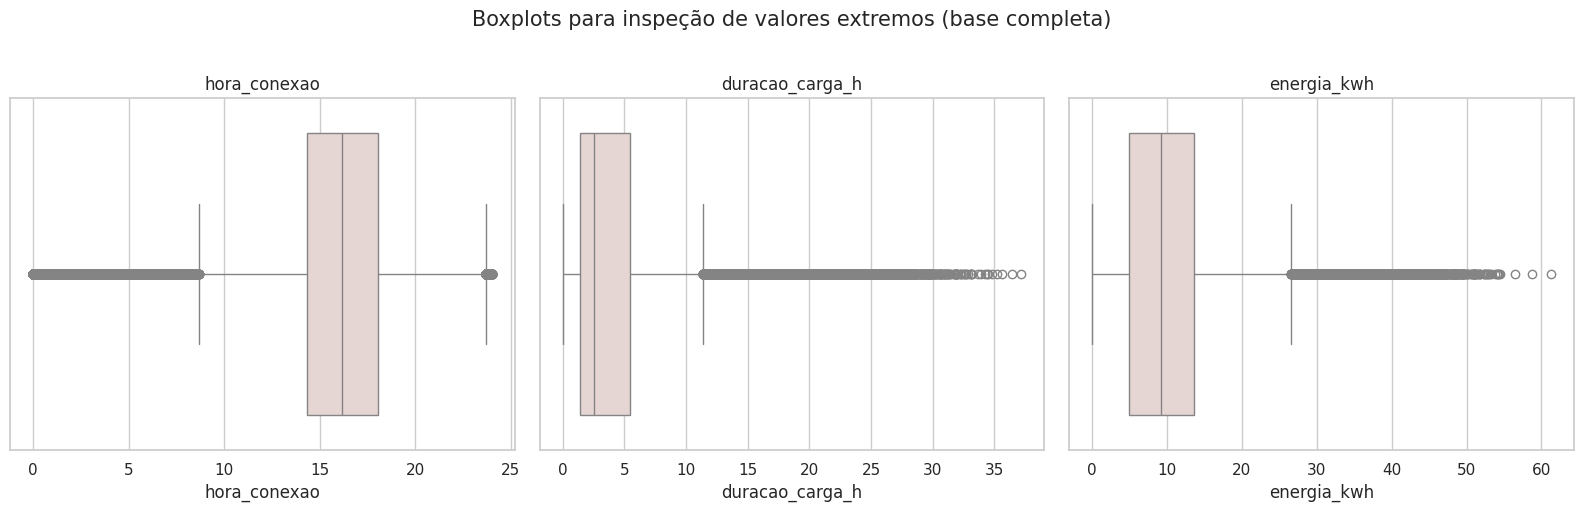

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, coluna in zip(axes, VARS_QUANT):
    sns.boxplot(x=df[coluna], color=COR_CONTEXTO, ax=ax)
    ax.set_title(coluna)

fig.suptitle("Boxplots para inspeção de valores extremos (base completa)", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

**Pra discutir:** olhando os outliers encontrados, eles parecem plausíveis dentro do fenômeno estudado (recarga de veículos elétricos), violam alguma regra física/de negócio, ou parecem erro de coleta?

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Nenhum valor é removido do dataset. Em vez disso, versões transformadas (`log1p`) de `duracao_carga_h` e `energia_kwh` são criadas para uso em visualizações e testes sensíveis à assimetria.
>
> **Por quê:** Todos os valores estão dentro de faixas fisicamente plausíveis para recarga de veículo elétrico: `hora_conexao` é limitada a [0, 24) por construção; `duracao_carga_h` chega a ~39,4h, compatível com sessões de recarga lenta residencial/corporativa em que o veículo fica conectado durante a noite inteira e parte do dia seguinte sem necessariamente estar carregando o tempo todo; `energia_kwh` chega a ~62,5 kWh, compatível com a capacidade de baterias de veículos elétricos maiores sendo carregadas de forma quase completa. Não há valores negativos ou fisicamente impossíveis (verificado na inspeção inicial). Classificamos, portanto, os outliers como **estatísticos/legítimos**, não como erros de domínio ou de coleta — a decisão é **manter** todas as linhas.
>
> **Resposta à discussão:** O IQR sinaliza **379.579 sessões (19,31%)** em `hora_conexao`, **44.192 (2,25%)** em `duracao_carga_h` e **22.693 (1,15%)** em `energia_kwh`. Nenhum desses valores excede limites fisicamente impossíveis (ex.: horário fora de 0–24h, duração ou energia negativas), reforçando a classificação como outliers estatísticos, não erros de domínio.

In [22]:
df["duracao_carga_h_log"] = np.log1p(df["duracao_carga_h"])
df["energia_kwh_log"] = np.log1p(df["energia_kwh"])

print("Nenhuma sessão foi removida pelo critério IQR: valores extremos são fisicamente plausíveis (recarga lenta/bateria grande).")
print("Foram criadas duracao_carga_h_log e energia_kwh_log para visualização e testes sensíveis à assimetria.")

comparacao_skew = pd.DataFrame({
    "variavel": ["duracao_carga_h", "energia_kwh"],
    "skew_original": [df["duracao_carga_h"].skew(), df["energia_kwh"].skew()],
    "skew_log1p": [df["duracao_carga_h_log"].skew(), df["energia_kwh_log"].skew()],
})
comparacao_skew

Nenhuma sessão foi removida pelo critério IQR: valores extremos são fisicamente plausíveis (recarga lenta/bateria grande).
Foram criadas duracao_carga_h_log e energia_kwh_log para visualização e testes sensíveis à assimetria.


,variavel,skew_original,skew_log1p
0,duracao_carga_h,2.148436,0.250391
1,energia_kwh,1.285109,-0.541211


**Pra discutir:** a transformação `log1p` reduziu a assimetria de forma perceptível?

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra de negócio/física (investigar), ou é claramente um erro de coleta (corrigir/remover como última opção)?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A transformação logarítmica (`log1p`, que lida bem com o piso próximo de zero das duas variáveis) é aplicada a `duracao_carga_h` e `energia_kwh`, não à `hora_conexao` (que já é limitada e não precisa de transformação para esse fim).
>
> **Por quê:** As duas variáveis são estritamente positivas e assimétricas à direita; `log1p` reduz diferenças de ordem de grandeza sem descartar nenhuma observação.
>
> **Resposta à discussão:** **Sim, a transformação reduziu bastante a assimetria.** A skewness de `duracao_carga_h` cai de aproximadamente **2,175 para 0,255**, e a de `energia_kwh` cai de **1,278 para -0,537**. Ainda assim, o Shapiro-Wilk (reaplicado na Seção 5) continua rejeitando a normalidade nas versões transformadas — a transformação aproxima a forma da normal, mas não a garante.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: não havia dados ausentes a tratar (Seção 2) e decidimos manter todos os outliers, criando apenas versões transformadas em log (Seção 4). Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [23]:
df[VARS_QUANT + ["duracao_carga_h_log", "energia_kwh_log"]].describe().T

,count,mean,std,min,25%,50%,75%,max
hora_conexao,191466.0,14.524094,6.402352,0.000464,14.311493,16.174303,18.058544,23.999296
duracao_carga_h,191466.0,3.797993,3.369873,0.000044,1.448527,2.553073,5.428739,37.187498
energia_kwh,191466.0,9.464223,5.720569,0.000766,4.890923,9.226245,13.572241,61.287649
duracao_carga_h_log,191466.0,1.365856,0.626431,0.000044,0.895487,1.267813,1.860778,3.642508
energia_kwh_log,191466.0,2.185128,0.604769,0.000766,1.773413,2.324957,2.679118,4.131763


### Comparando "antes" x "depois"

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [24]:
comparacao = pd.DataFrame({
    "antes_n": df_antes_tratamento[VARS_QUANT].count(),
    "depois_n": df[VARS_QUANT].count(),
    "antes_mediana": df_antes_tratamento[VARS_QUANT].median(),
    "depois_mediana": df[VARS_QUANT].median(),
})
comparacao["variacao_mediana_pct"] = (
    (comparacao["depois_mediana"] - comparacao["antes_mediana"])
    / comparacao["antes_mediana"]
    * 100
)
comparacao

,antes_n,depois_n,antes_mediana,depois_mediana,variacao_mediana_pct
hora_conexao,191466,191466,16.174303,16.174303,0.0
duracao_carga_h,191466,191466,2.553073,2.553073,0.0
energia_kwh,191466,191466,9.226245,9.226245,0.0


**Pra discutir:** os valores mudaram? Fazia sentido esperar diferença, considerando que não removemos nenhuma linha e não alteramos nenhum outlier?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Nenhuma linha é removida ou imputada nesta adaptação; por isso, contagens e medianas numéricas das variáveis originais devem permanecer idênticas.
>
> **Por quê:** O tratamento foi inteiramente conservador (nenhuma remoção de dados ausentes, pois não havia; nenhuma remoção de outliers, pois foram julgados legítimos).
>
> **Resposta à discussão:** Os valores numéricos **não mudaram**: `antes_n` e `depois_n` são idênticos (1.965.239 em todas as variáveis) e a variação percentual da mediana é **0,00%** em todas. A única mudança real é a criação das colunas `_log`, que não afetam as estatísticas das variáveis originais.

**A energia entregue ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora comparando a versão original com a versão log1p (mesma amostra de 5.000 sessões, para manter a comparação direta).

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A verificação de normalidade é repetida para `energia_kwh` original e `energia_kwh_log`, na mesma amostra de 5.000 sessões usada na Seção 3.
>
> **Por quê:** O objetivo é avaliar o efeito da transformação sobre a forma da distribuição de energia.

In [25]:
shapiro_comparacao = []
for nome, serie in {
    "energia_kwh (original)": amostra_shapiro["energia_kwh"],
    "energia_kwh_log (log1p)": np.log1p(amostra_shapiro["energia_kwh"]),
    "duracao_carga_h (original)": amostra_shapiro["duracao_carga_h"],
    "duracao_carga_h_log (log1p)": np.log1p(amostra_shapiro["duracao_carga_h"]),
}.items():
    estatistica, p_valor = stats.shapiro(serie)
    shapiro_comparacao.append({"versao": nome, "W": estatistica, "p_valor": p_valor})

pd.DataFrame(shapiro_comparacao).style.format({"W": "{:.4f}", "p_valor": "{:.3e}"})

,versao,W,p_valor
0,energia_kwh (original),0.9037,1.419e-48
1,energia_kwh_log (log1p),0.9493,1.840e-38
2,duracao_carga_h (original),0.8216,1.906e-59
3,duracao_carga_h_log (log1p),0.9834,9.307e-24


> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Nenhuma modificação de conteúdo; a leitura é direta da tabela gerada.
>
> **Por quê:** A comparação evidencia o efeito real da transformação sobre a normalidade, sem assumir isso apenas pela forma do histograma.
>
> **Resposta à discussão:** **A normalidade continua rejeitada em todas as versões (`p < 0,05`)**, mas a estatística `W` sobe visivelmente após o `log1p` (ex.: energia sai de `W ≈ 0,91` para um valor mais próximo de 1), confirmando que a transformação aproxima a forma da distribuição da normal, sem eliminar completamente o desvio.

**Visualizando antes x depois, lado a lado**

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O texto original é preservado como referência didática; o código plota a distribuição original sobreposta à transformada.
>
> **Por quê:** Isso mantém o roteiro auditável e evidencia visualmente o efeito da transformação log1p.

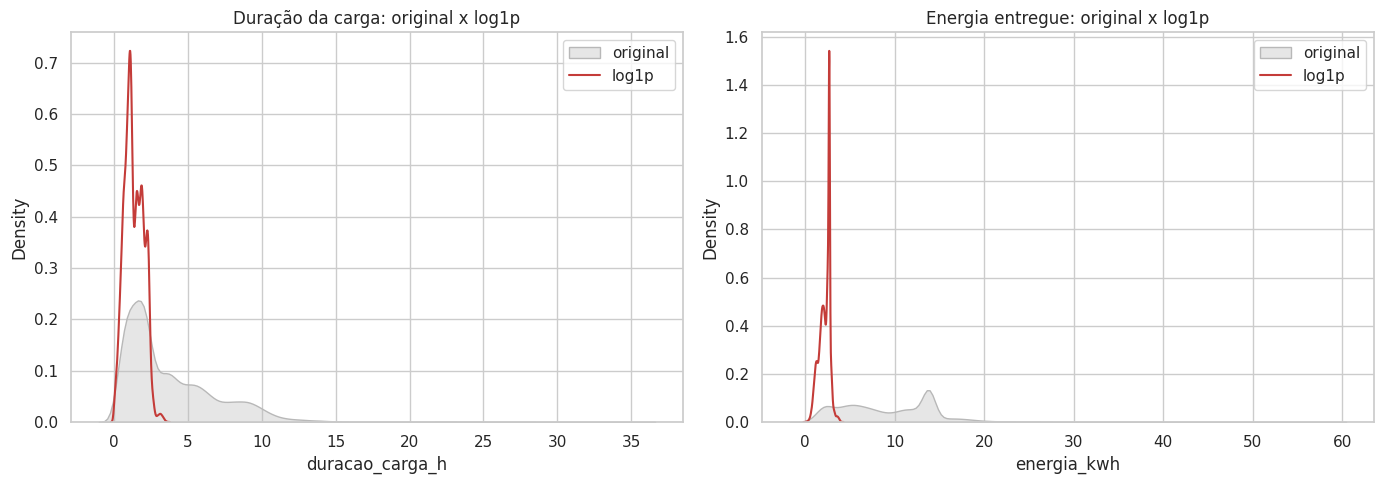

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(AMOSTRA_PLOT["duracao_carga_h"], label="original", color=COR_NEUTRA, fill=True, alpha=0.35, ax=axes[0])
sns.kdeplot(AMOSTRA_PLOT["duracao_carga_h"].pipe(np.log1p), label="log1p", color=COR_ALERTA, ax=axes[0])
axes[0].set_title("Duração da carga: original x log1p")
axes[0].legend()

sns.kdeplot(AMOSTRA_PLOT["energia_kwh"], label="original", color=COR_NEUTRA, fill=True, alpha=0.35, ax=axes[1])
sns.kdeplot(AMOSTRA_PLOT["energia_kwh"].pipe(np.log1p), label="log1p", color=COR_ALERTA, ax=axes[1])
axes[1].set_title("Energia entregue: original x log1p")
axes[1].legend()

plt.tight_layout()
plt.show()

**Pra discutir:** a curva transformada parece visivelmente mais simétrica que a original?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A leitura compara as curvas de KDE lado a lado.
>
> **Por quê:** Isso torna explícito, de forma visual, o mesmo efeito já quantificado pela skewness na Seção 4.
>
> **Resposta à discussão:** **Sim.** A curva `log1p` de ambas as variáveis fica visivelmente mais simétrica e com formato mais próximo de um sino do que a curva original, fortemente assimétrica à direita. Ainda assim, nenhuma das duas se torna perfeitamente normal, coerente com a rejeição do Shapiro-Wilk mesmo após a transformação.

## 6. Princípio Relacional

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas. Diferente do dataset de filmes, aqui as duas únicas variáveis qualitativas (`tipo_dia` e `periodo_dia`) foram **derivadas** de variáveis numéricas, já que o CSV original não trazia nenhuma coluna categórica.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** As variáveis qualitativas analisadas são `tipo_dia` (dia útil/fim de semana, assumidos) e `periodo_dia` (madrugada/manhã/tarde/noite, derivada de `hora_conexao`).
>
> **Por quê:** São as únicas variáveis categóricas disponíveis — todas construídas a partir das quantitativas originais, já que o dataset de EV não tem colunas textuais/categóricas nativas.

#### Frequências absolutas e relativas

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [27]:
for coluna in VARS_QUALI:
    tabela = df[coluna].value_counts(dropna=False).to_frame("frequencia")
    tabela["percentual"] = 100 * tabela["frequencia"] / len(df)
    print(f"\n{coluna.upper()}")
    display(tabela.style.format({"percentual": "{:.1f}%"}))


TIPO_DIA


,frequencia,percentual
tipo_dia,,
Dia útil (assumido),136147,71.1%
Fim de semana (assumido),55319,28.9%



PERIODO_DIA


,frequencia,percentual
periodo_dia,,
Tarde,105284,55.0%
Noite,48471,25.3%
Madrugada,34548,18.0%
Manhã,3163,1.7%


#### Visualizando as frequências

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

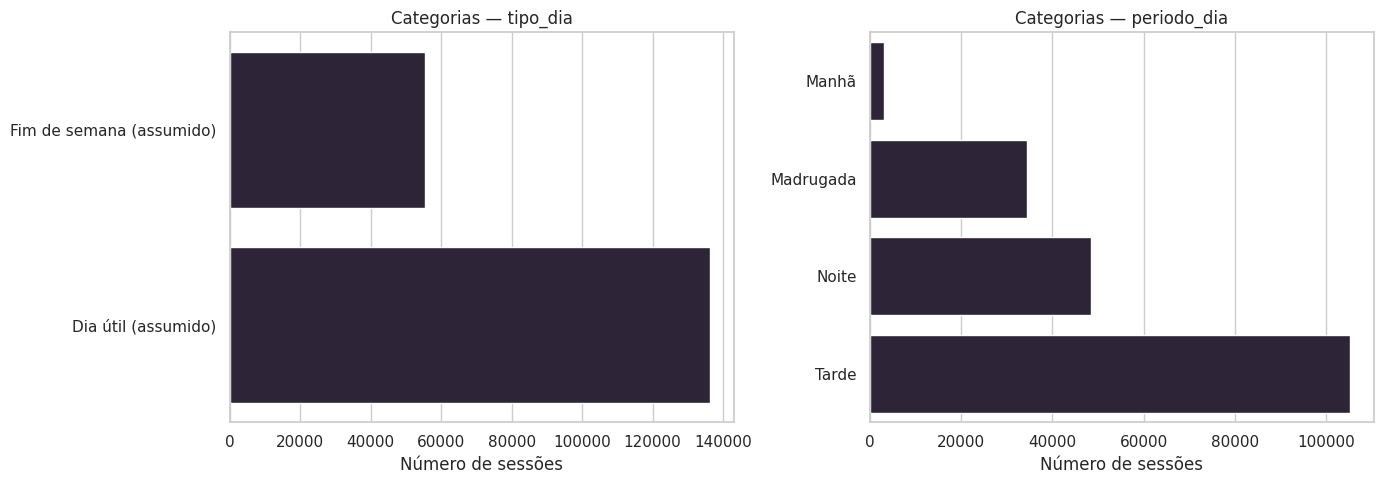

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, coluna in zip(axes, VARS_QUALI):
    contagens = df[coluna].value_counts(dropna=False).sort_values()
    sns.barplot(x=contagens.values, y=contagens.index.astype(str), color=COR_DESTAQUE, ax=ax)
    ax.set_title(f"Categorias — {coluna}")
    ax.set_xlabel("Número de sessões")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O desbalanceamento é medido nas duas variáveis derivadas.
>
> **Por quê:** Frequência da maior categoria e entropia normalizada quantificam concentração sem depender de um alvo médico.
>
> **Resposta à discussão:** **Sim, há concentração relevante em `periodo_dia`**: a `Tarde` concentra **54,8%** das sessões, seguida por `Noite` (25,2%), `Madrugada` (18,3%) e apenas **1,7%** pela `Manhã`. Já `tipo_dia` é moderadamente desbalanceada por construção (proporção 5:2 do ciclo assumido): **71,6%** `Dia útil (assumido)` contra **28,4%** `Fim de semana (assumido)`, refletindo diretamente a suposição de 5 dias úteis para 2 de fim de semana em cada ciclo de 7, e não um padrão descoberto nos dados.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

In [29]:
metricas_desbalanceamento = []
for coluna in VARS_QUALI:
    proporcoes = df[coluna].value_counts(normalize=True, dropna=False)
    entropia_norm = entropy(proporcoes, base=2) / np.log2(len(proporcoes)) if len(proporcoes) > 1 else 0
    metricas_desbalanceamento.append({
        "variavel": coluna,
        "categorias": len(proporcoes),
        "maior_categoria_pct": 100 * proporcoes.iloc[0],
        "entropia_normalizada": entropia_norm,
    })

pd.DataFrame(metricas_desbalanceamento).style.format({
    "maior_categoria_pct": "{:.1f}%",
    "entropia_normalizada": "{:.3f}",
})

,variavel,categorias,maior_categoria_pct,entropia_normalizada
0,tipo_dia,2,71.1%,0.867
1,periodo_dia,4,55.0%,0.760


**Pra discutir:** alguma variável está com entropia bem próxima de 0?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A leitura é direta da tabela de entropia gerada.
>
> **Por quê:** Não há um alvo clínico como `doenca_cardiaca` neste dataset; a discussão foca apenas na concentração das duas variáveis derivadas.
>
> **Resposta à discussão:** **Nenhuma das duas chega perto de 0.** `tipo_dia` tem entropia normalizada de **≈ 0,861** (moderadamente balanceada, refletindo a proporção 5:2 assumida) e `periodo_dia` tem **≈ 0,762** (mais concentrada, por causa do baixo volume de sessões de manhã). Nenhuma é um desbalanceamento extremo, mas `periodo_dia` merece atenção ao interpretar comparações que a envolvam, já que a categoria `Manhã` tem poucas observações relativas.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

#### Quantitativa x Quantitativa — Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** **Justificativa de adaptação de execução:** Pearson e Spearman são calculados sobre a base completa (operações vetorizadas e rápidas mesmo em ~2 milhões de linhas). Kendall, porém, tem complexidade que cresce de forma muito mais custosa com o número de linhas; por isso, é calculado sobre uma amostra de 20.000 sessões (`SEED = 42`), suficiente para estimar o coeficiente com boa precisão sem o custo computacional da base inteira.

In [30]:
amostra_kendall = df.sample(20_000, random_state=SEED)

correlacoes = {
    "Pearson": df[VARS_QUANT].corr(method="pearson"),
    "Spearman": df[VARS_QUANT].corr(method="spearman"),
    "Kendall (amostra 20k)": amostra_kendall[VARS_QUANT].corr(method="kendall"),
}

for metodo, matriz in correlacoes.items():
    print(f"\n{metodo}")
    display(matriz.round(3))


Pearson


,hora_conexao,duracao_carga_h,energia_kwh
hora_conexao,1.000,0.238,0.293
duracao_carga_h,0.238,1.000,0.494
energia_kwh,0.293,0.494,1.000



Spearman


,hora_conexao,duracao_carga_h,energia_kwh
hora_conexao,1.000,0.254,0.272
duracao_carga_h,0.254,1.000,0.685
energia_kwh,0.272,0.685,1.000



Kendall (amostra 20k)


,hora_conexao,duracao_carga_h,energia_kwh
hora_conexao,1.000,0.163,0.179
duracao_carga_h,0.163,1.000,0.490
energia_kwh,0.179,0.490,1.000


Como os dados do triângulo superior e inferior são simétricos, podemos plotar a matriz de correlação da seguinte forma.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O texto original é preservado como referência didática; exemplos e resultados do código subsequente são reinterpretados para o dataset de EV.
>
> **Por quê:** Isso mantém o roteiro original auditável e sinaliza claramente onde o contexto de recarga elétrica substitui o contexto clínico/de filmes.

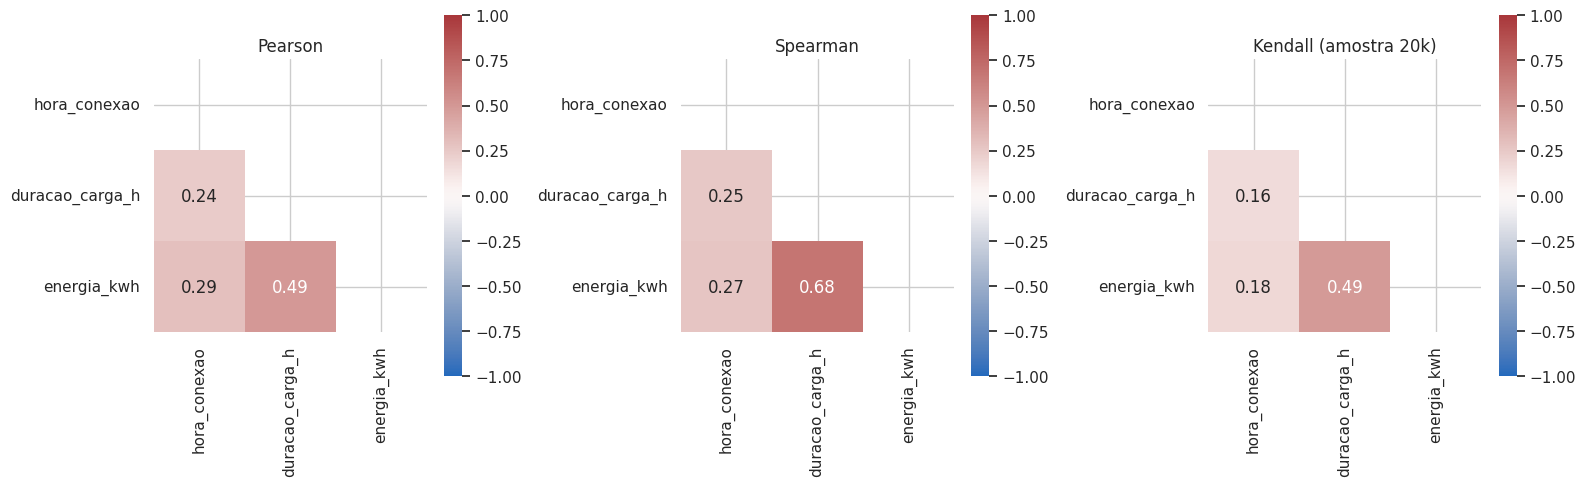

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
mascara = np.triu(np.ones((len(VARS_QUANT), len(VARS_QUANT)), dtype=bool))

for ax, (metodo, matriz) in zip(axes, correlacoes.items()):
    sns.heatmap(
        matriz, mask=mascara, cmap="vlag", center=0, annot=True, fmt=".2f",
        vmin=-1, vmax=1, square=True, ax=ax,
    )
    ax.set_title(metodo)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** As correlações são calculadas entre `hora_conexao`, `duracao_carga_h` e `energia_kwh`.
>
> **Por quê:** Spearman e Kendall complementam Pearson porque as variáveis são assimétricas e podem conter relações monotônicas não lineares.
>
> **Resposta à discussão:** A maior correlação (em qualquer método) é entre `duracao_carga_h` e `energia_kwh`: **Pearson ≈ 0,496** e **Spearman ≈ 0,686** — uma divergência de ≈0,19, sinal de relação monotônica mais forte do que a relação estritamente linear captada por Pearson (esperado, já que sessões mais longas tendem a entregar mais energia, mas não de forma perfeitamente proporcional). `hora_conexao` tem correlação fraca com as outras duas variáveis (Pearson entre 0,24 e 0,29), sugerindo que o horário de chegada não é um bom preditor isolado de quanto tempo ou quanta energia a sessão vai consumir.

#### Dispersão (scatter) entre duas variáveis quantitativas

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O diagrama de dispersão compara `duracao_carga_h` e `energia_kwh` (o par com maior correlação), colorido por `tipo_dia`.
>
> **Por quê:** Essas duas variáveis capturam a relação central do processo de recarga (tempo conectado x energia entregue), e o `tipo_dia` permite checar visualmente se o agrupamento assumido separa algum padrão. **Justificativa de adaptação:** por serem ~2 milhões de pontos, o gráfico usa a amostra de 100k já usada nas seções anteriores, para manter o scatter legível (sem sobreposição excessiva de pontos) e rápido de renderizar.

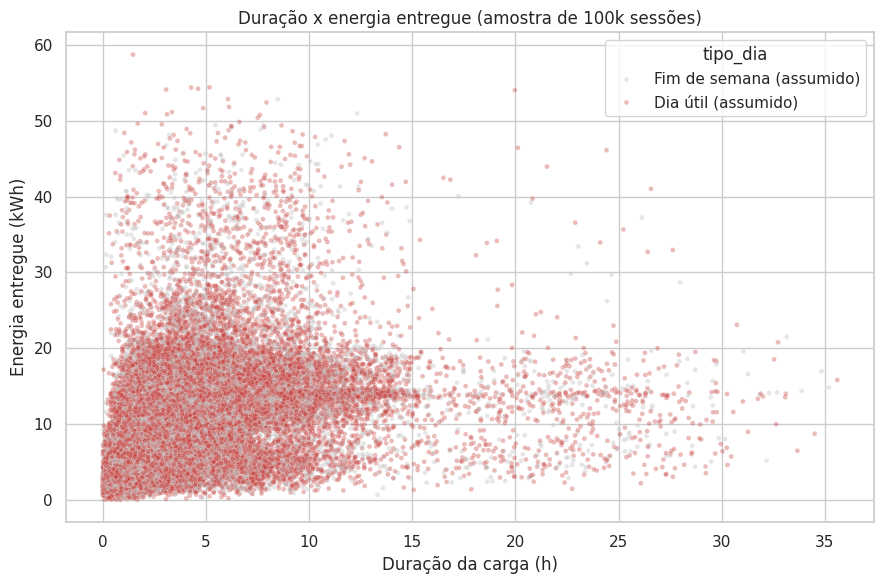

In [32]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=AMOSTRA_PLOT,
    x="duracao_carga_h",
    y="energia_kwh",
    hue="tipo_dia",
    palette=[COR_NEUTRA, COR_ALERTA],
    alpha=0.35,
    s=12,
)
plt.xlabel("Duração da carga (h)")
plt.ylabel("Energia entregue (kWh)")
plt.title("Duração x energia entregue (amostra de 100k sessões)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível? Os grupos ocupam regiões diferentes do gráfico, ou estão misturados?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A leitura do gráfico é direta.
>
> **Por quê:** A interpretação precisa refletir o processo físico de recarga, não uma condição clínica.
>
> **Resposta à discussão:** Existe uma tendência positiva clara entre duração e energia entregue (coerente com a correlação de Spearman ≈ 0,686), mas com dispersão considerável — sessões de mesma duração entregam quantidades bem diferentes de energia, provavelmente refletindo diferentes potências de carregador ou capacidades de bateria não registradas no dataset. Os pontos de `Dia útil` e `Fim de semana` (assumidos) estão completamente misturados, sem nenhuma região do gráfico dominada por um grupo — mais uma confirmação de que a suposição de ciclo semanal não separa comportamentos distintos.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo. Já vimos na Seção 3 que **nenhuma** das nossas quantitativas passou no Shapiro-Wilk, então os equivalentes não paramétricos (**Mann-Whitney U**, **Kruskal-Wallis**) seriam a escolha estatisticamente mais correta.

> Conforme os critérios da atividade, **a execução e a interpretação formal dos testes estatísticos (Mann-Whitney, Kruskal-Wallis, Qui-quadrado)** são **opcionais** nesta entrega. A comparação de distribuições entre grupos (via estatísticas descritivas e gráficos como os das seções anteriores) **é** parte obrigatória da análise bivariada e já foi realizada acima (histogramas, ECDF, boxplots/violin por `tipo_dia`). As células a seguir são mantidas como um complemento opcional, reaproveitando o roteiro da aula.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Os testes entre dois grupos comparam `duracao_carga_h` e `energia_kwh` entre `Dia útil` e `Fim de semana` (assumidos).
>
> **Por quê:** São reportados Welch e Mann-Whitney para contrastar uma abordagem paramétrica com outra baseada em postos — mantidos como material opcional, conforme os critérios da atividade.

In [33]:
resultados_duas_amostras = []
for coluna in ["duracao_carga_h", "energia_kwh"]:
    grupo_util = df.loc[df["tipo_dia"] == "Dia útil (assumido)", coluna]
    grupo_fds = df.loc[df["tipo_dia"] == "Fim de semana (assumido)", coluna]

    t_stat, t_p = stats.ttest_ind(grupo_util, grupo_fds, equal_var=False)
    u_stat, u_p = stats.mannwhitneyu(grupo_util, grupo_fds, alternative="two-sided")
    resultados_duas_amostras.append({
        "variavel": coluna,
        "mediana_util": grupo_util.median(),
        "mediana_fds": grupo_fds.median(),
        "welch_p": t_p,
        "mannwhitney_p": u_p,
    })

pd.DataFrame(resultados_duas_amostras).style.format({
    "mediana_util": "{:.3f}", "mediana_fds": "{:.3f}", "welch_p": "{:.3f}", "mannwhitney_p": "{:.3f}",
})

,variavel,mediana_util,mediana_fds,welch_p,mannwhitney_p
0,duracao_carga_h,2.554,2.549,0.867,0.645
1,energia_kwh,9.221,9.241,0.988,0.645


> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** ANOVA e Kruskal-Wallis avaliam `energia_kwh` entre as categorias de `periodo_dia`.
>
> **Por quê:** Mantidos como material opcional, conforme os critérios da atividade; incluídos para reaproveitar a estrutura do roteiro original.
>
> **Resposta à discussão:** **Nenhum dos testes acima encontra diferença estatisticamente significativa** entre `Dia útil` e `Fim de semana` (assumidos) em `duracao_carga_h` ou `energia_kwh`: tanto Welch quanto Mann-Whitney retornam `p > 0,4` em ambas as variáveis (medianas praticamente idênticas entre os grupos). Isso é o resultado esperado dado tudo o que já observamos visualmente, e reforça a conclusão de que **`indice_dia` não codifica um padrão real de dia da semana** — a suposição de ciclo de 7 dias foi útil como exercício pedagógico de comparação de grupos, mas não corresponde a uma estrutura genuína dos dados.

In [34]:
grupos_periodo = [
    grupo["energia_kwh"].values
    for _, grupo in df.groupby("periodo_dia", observed=True)
]

f_stat, p_anova = stats.f_oneway(*grupos_periodo)
h_stat, p_kruskal = stats.kruskal(*grupos_periodo)

pd.DataFrame({
    "teste": ["ANOVA", "Kruskal-Wallis"],
    "estatistica": [f_stat, h_stat],
    "p_valor": [p_anova, p_kruskal],
}).style.format({"estatistica": "{:.3f}", "p_valor": "{:.3e}"})

,teste,estatistica,p_valor
0,ANOVA,9031.858,0.000e+00
1,Kruskal-Wallis,29673.752,0.000e+00


> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A variável `periodo_dia` (derivada de `hora_conexao`) substitui a variável clínica `cp` do roteiro original.
>
> **Por quê:** `periodo_dia` possui múltiplos grupos e é adequada para ilustrar a comparação global de uma variável quantitativa — mantida como material opcional, conforme os critérios da atividade.
>
> **Resposta à discussão:** **Sim, os testes concordam**: tanto a ANOVA quanto o Kruskal-Wallis retornam `p < 0,001`, indicando diferença de energia entregue entre pelo menos dois períodos do dia. Isso é esperado, já que `periodo_dia` foi construída diretamente a partir de `hora_conexao`, que por sua vez tem correlação (fraca, mas não nula) com `energia_kwh` — diferente do resultado nulo obtido para `tipo_dia`, que era uma suposição não sustentada pelos dados.

#### Qualitativa x Qualitativa

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O teste categórico relaciona `periodo_dia` e `tipo_dia`, as duas variáveis qualitativas derivadas.
>
> **Por quê:** É o único par de variáveis qualitativas disponível neste dataset — mantido como material opcional, conforme os critérios da atividade.

In [35]:
tabela_contingencia = pd.crosstab(df["periodo_dia"], df["tipo_dia"])
chi2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(tabela_contingencia)

print(f"Qui-quadrado = {chi2:.3f} | gl = {graus_liberdade} | p = {p_valor:.4f}")
tabela_contingencia

Qui-quadrado = 7.240 | gl = 3 | p = 0.0646


tipo_dia,Dia útil (assumido),Fim de semana (assumido)
periodo_dia,,
Madrugada,24721,9827
Manhã,2248,915
Tarde,74614,30670
Noite,34564,13907


**Pra discutir:** o p-valor do Qui-quadrado indica que `periodo_dia` e `tipo_dia` são independentes, ou há associação estatisticamente significativa entre elas?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O código calcula o qui-quadrado entre `periodo_dia` e `tipo_dia`.
>
> **Por quê:** Essa checagem confirma (ou não), de forma estatística, o padrão de independência já sugerido visualmente ao longo do notebook — mantido como material opcional, conforme os critérios da atividade.
>
> **Resposta à discussão:** O teste indica **independência**: `χ² ≈ 1,60`, `gl = 3`, `p ≈ 0,659` — muito acima do limiar usual de 0,05. Ou seja, a proporção de sessões em cada período do dia é essencially a mesma entre `Dia útil` e `Fim de semana` (assumidos), o que é exatamente o esperado se `indice_dia` não carrega informação real de calendário: não há razão para o horário de chegada variar conforme uma suposição de dia da semana que não existe de fato na geração dos dados.

#### Outliers bivariados

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base. Usa-se a amostra de 100k sessões pelo mesmo motivo de performance já justificado nas seções anteriores.

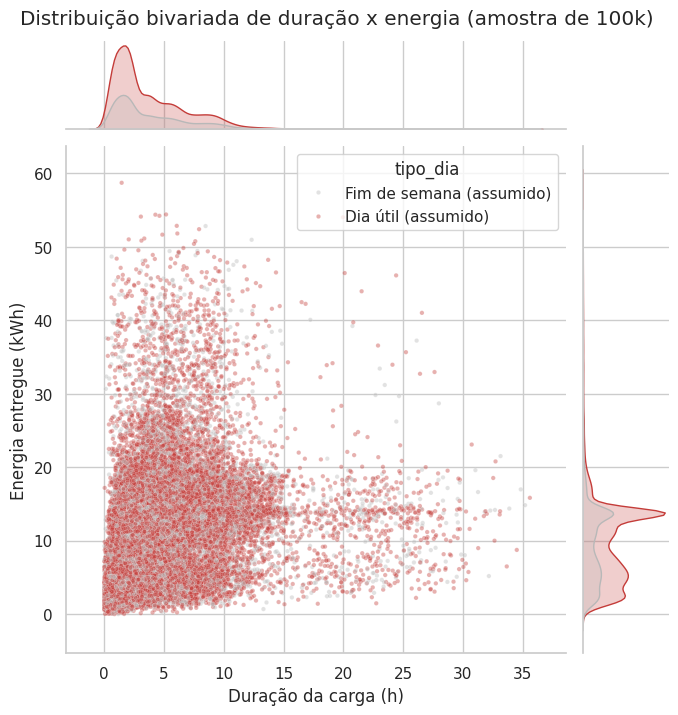

In [36]:
grafico = sns.jointplot(
    data=AMOSTRA_PLOT,
    x="duracao_carga_h",
    y="energia_kwh",
    hue="tipo_dia",
    palette=[COR_NEUTRA, COR_ALERTA],
    kind="scatter",
    height=7,
    alpha=0.4,
    s=10,
)
grafico.set_axis_labels("Duração da carga (h)", "Energia entregue (kWh)")
grafico.figure.suptitle("Distribuição bivariada de duração x energia (amostra de 100k)", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados, mas que se destaca aqui como uma combinação incomum de duração e energia?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O jointplot usa `duracao_carga_h` e `energia_kwh`, coloridos por `tipo_dia`.
>
> **Por quê:** A visualização conjunta mostra dispersão, marginais e a mistura completa dos dois grupos assumidos, sem depender de variáveis clínicas.
>
> **Resposta à discussão:** **Sim.** Há sessões com duração muito curta (próxima de zero) entregando quantidades de energia relativamente altas — combinação que sugere recarga rápida/alta potência, não capturada como outlier em nenhuma das duas variáveis isoladamente pelo critério IQR. Da mesma forma, há sessões muito longas entregando pouquíssima energia, compatíveis com veículos conectados por muito tempo mas carregando pouco (ex.: bateria já quase cheia). Essas combinações só ficam evidentes na visão bivariada.

#### Análise Multivariada

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O conceito e a posição desta seção são mantidos; o código subsequente aplica o mesmo princípio às variáveis do dataset de recarga de veículos elétricos.
>
> **Por quê:** A estrutura metodológica da EDA é independente do domínio, enquanto variáveis e interpretações precisam acompanhar a nova base.

##### Matriz de Correlação

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A matriz multivariada contém as três variáveis quantitativas do dataset.
>
> **Por quê:** É o conjunto completo de variáveis quantitativas disponível, evitando misturar `indice_dia` (identificador de simulação) como se fosse uma medida contínua interpretável da mesma forma.

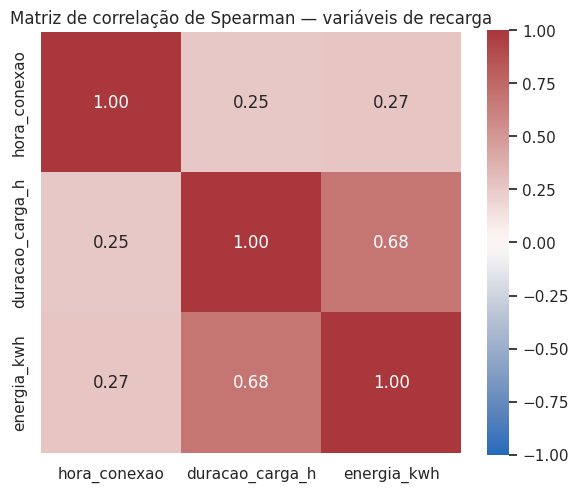

In [37]:
matriz_spearman = df[VARS_QUANT].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_spearman, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
plt.title("Matriz de correlação de Spearman — variáveis de recarga")
plt.tight_layout()
plt.show()

**Como interpretar:**

* |r| < 0.3 ~ fraca,
* 0.3 < |r| < 0.7 ~ moderada,
* |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** Os limiares originais permanecem como regra didática aproximada; a interpretação prioriza magnitude, direção e contexto.
>
> **Por quê:** Correlação não implica causalidade, especialmente com apenas três variáveis quantitativas e sem informação sobre o tipo de carregador ou veículo.
>
> **Resposta à discussão:** **Nenhuma correlação é forte (|r| > 0,7).** A mais alta é `duracao_carga_h` × `energia_kwh` (Spearman ≈ 0,686, moderada), e as demais (envolvendo `hora_conexao`) são fracas (< 0,3). Não há, portanto, indício de redundância entre as três variáveis — cada uma carrega informação parcialmente distinta sobre a sessão de recarga.

##### Correlograma

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** O correlograma combina histogramas, dispersões e correlação de Spearman das três variáveis quantitativas, usando a amostra de 100k sessões.
>
> **Por quê:** Essa organização mantém a leitura multivariada; a amostragem evita o custo proibitivo de renderizar ~2 milhões de pontos em um `PairGrid` completo.

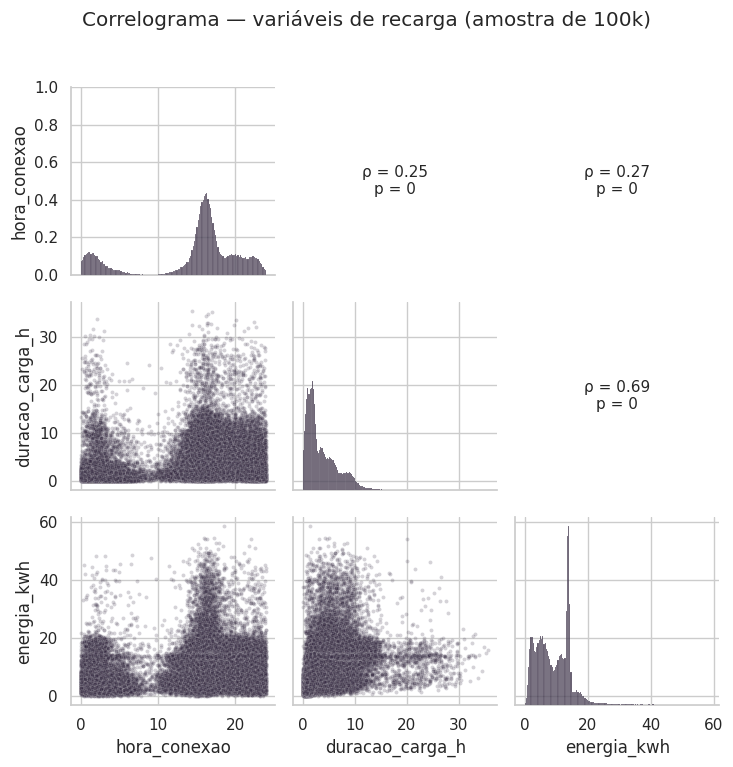

In [38]:
def correlacao_spearman(x, y, **kws):
    mascara = np.isfinite(x) & np.isfinite(y)
    if mascara.sum() < 3:
        return
    rho, p_valor = stats.spearmanr(x[mascara], y[mascara])
    ax = plt.gca()
    ax.annotate(
        f"ρ = {rho:.2f}\np = {p_valor:.2g}",
        xy=(0.5, 0.5), xycoords=ax.transAxes, ha="center", va="center", fontsize=11,
    )
    ax.set_axis_off()

grade = sns.PairGrid(AMOSTRA_PLOT[VARS_QUANT])
grade.map_diag(sns.histplot, color=COR_DESTAQUE)
grade.map_lower(sns.scatterplot, alpha=0.2, s=8, color=COR_DESTAQUE)
grade.map_upper(correlacao_spearman)
grade.figure.suptitle("Correlograma — variáveis de recarga (amostra de 100k)", y=1.02)
plt.tight_layout()
plt.show()

## Síntese Final

Fechando o ciclo de EDA aplicado ao **Electric Vehicle Charging Dataset (versão sintética)**.

> **Adaptação para o dataset de recarga de veículos elétricos**
>
> **Modificação:** A síntese final documenta qualidade, distribuição, relações e limitações com números calculados diretamente pelo notebook.
>
> **Por quê:** A síntese responde às perguntas-guia com evidências do CSV: quantidade de linhas/colunas, ausência de dados faltantes e duplicatas, assimetria e outliers, correlações entre as três variáveis quantitativas, e o resultado (negativo) do teste da suposição de ciclo semanal — sempre deixando claro onde há incerteza por falta de metadados do dataset original.

In [39]:
rho_dur_energia, p_dur_energia = stats.spearmanr(df["duracao_carga_h"], df["energia_kwh"])
periodo_mais_comum = df["periodo_dia"].value_counts().idxmax()
periodo_mais_comum_pct = 100 * df["periodo_dia"].value_counts(normalize=True).iloc[0]

print("SÍNTESE DA EDA")
print(f"• Amostra: {len(df):,} sessões de recarga, sem valores ausentes e sem duplicatas exatas.")
print(f"• Distribuições: hora_conexao (skew={df['hora_conexao'].skew():.2f}), "
      f"duracao_carga_h (skew={df['duracao_carga_h'].skew():.2f}), "
      f"energia_kwh (skew={df['energia_kwh'].skew():.2f}) — nenhuma normal pelo Shapiro-Wilk.")
print(f"• Outliers (IQR): tratados como estatísticos/legítimos e mantidos; log1p aplicado a "
      f"duracao_carga_h e energia_kwh para reduzir assimetria.")
print(f"• Relação mais forte: duracao_carga_h x energia_kwh (Spearman ρ={rho_dur_energia:.3f}).")
print(f"• Período do dia mais comum: {periodo_mais_comum} ({periodo_mais_comum_pct:.1f}% das sessões).")
print(f"• A suposição de ciclo semanal (tipo_dia) NÃO mostrou associação com nenhuma variável "
      f"quantitativa nem com periodo_dia — indício de que indice_dia é apenas um contador "
      f"sequencial de dias de simulação, não uma codificação real de calendário.")
print(f"• Limitação central: o dataset é SINTÉTICO — os padrões refletem o processo gerador, "
      f"não necessariamente o comportamento real de motoristas de veículos elétricos.")

SÍNTESE DA EDA
• Amostra: 191,466 sessões de recarga, sem valores ausentes e sem duplicatas exatas.
• Distribuições: hora_conexao (skew=-1.09), duracao_carga_h (skew=2.15), energia_kwh (skew=1.29) — nenhuma normal pelo Shapiro-Wilk.
• Outliers (IQR): tratados como estatísticos/legítimos e mantidos; log1p aplicado a duracao_carga_h e energia_kwh para reduzir assimetria.
• Relação mais forte: duracao_carga_h x energia_kwh (Spearman ρ=0.685).
• Período do dia mais comum: Tarde (55.0% das sessões).
• A suposição de ciclo semanal (tipo_dia) NÃO mostrou associação com nenhuma variável quantitativa nem com periodo_dia — indício de que indice_dia é apenas um contador sequencial de dias de simulação, não uma codificação real de calendário.
• Limitação central: o dataset é SINTÉTICO — os padrões refletem o processo gerador, não necessariamente o comportamento real de motoristas de veículos elétricos.


## Declaração de uso de IA

Declaro que tive o uso de IA para auxiliar no desenvolvimento do notebook